In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


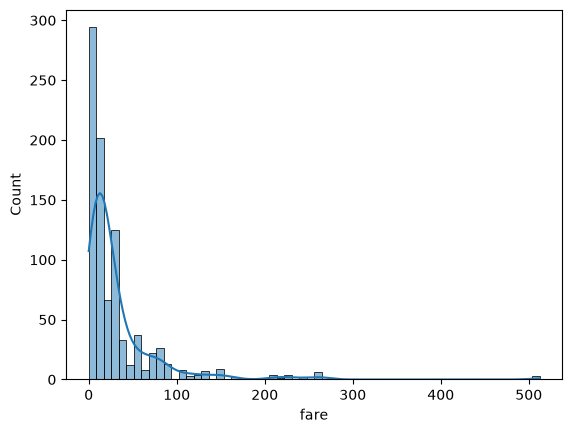

In [3]:
sns.histplot(df["fare"], kde=True)
plt.show()

In [4]:
df["fare"].skew()

np.float64(4.787316519674893)

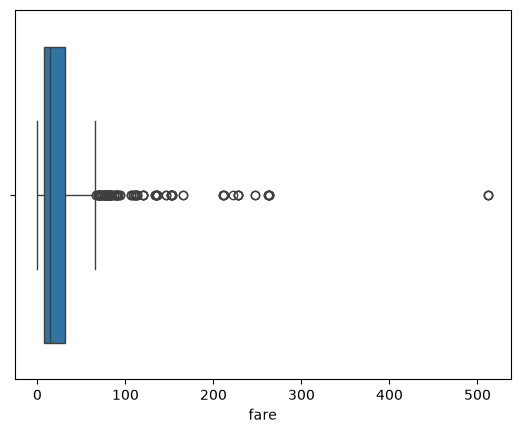

In [5]:
sns.boxplot(x=df["fare"])
plt.show()

In [6]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 7.9104
Q3: 31.0
IQR: 23.0896


In [7]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -26.724
Upper Bound: 65.6344


In [ ]:
outliers = df[
    (df["fare"] < lower_bound) |
    (df["fare"] > upper_bound)
]
print("Total observations:", len(df))

print("Outliers:", len(outliers))

print("Outlier percentage:",
      len(outliers) / len(df) * 100)

Total observations: 891
Outliers: 116
Outlier percentage: 13.019079685746352


In [11]:
df_no_outliers = df[
    (df["fare"] >= lower_bound) &
    (df["fare"] <= upper_bound)
]

print("Original shape:", df.shape)
print("After removing outliers:", df_no_outliers.shape)

Original shape: (891, 15)
After removing outliers: (775, 15)


In [12]:
from scipy.stats import zscore

df["z_score"] = zscore(df["fare"], nan_policy="omit")

outliers = df[df["z_score"].abs() > 3]

outliers[["fare", "z_score"]]

,fare,z_score
27,263.0000,4.647001
88,263.0000,4.647001
118,247.5208,4.335332
258,512.3292,9.667167
299,247.5208,4.335332
311,262.3750,4.634417
341,263.0000,4.647001
377,211.5000,3.610065
380,227.5250,3.932723
438,263.0000,4.647001


In [14]:
import numpy as np

median = df["fare"].median()

MAD = np.median(np.abs(df["fare"] - median))

df["modified_z_score"] = (
    0.6745 * (df["fare"] - median) / MAD
)

outliers = df[
    df["modified_z_score"].abs() > 3.5
]

outliers[["fare", "modified_z_score"]]

,fare,modified_z_score
1,71.2833,5.551871
3,53.1000,3.775469
6,51.8625,3.654572
27,263.0000,24.281472
31,146.5208,12.902135
...,...,...
856,164.8667,14.694422
863,69.5500,5.382538
867,50.4958,3.521054
871,52.5542,3.722147


In [16]:
print(df["fare"].quantile(0.01))
df["fare"].quantile(0.99)  

0.0


np.float64(249.00622000000035)

In [17]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)

IQR = Q3 - Q1

lower_inner = Q1 - 1.5 * IQR
upper_inner = Q3 + 1.5 * IQR


lower_outer = Q1 - 3 * IQR
upper_outer = Q3 + 3 * IQR

outliers = df[
    (df["fare"] < lower_inner) |
    (df["fare"] > upper_inner)
]

outliers[["fare"]]

,fare
1,71.2833
27,263.0000
31,146.5208
34,82.1708
52,76.7292
...,...
846,69.5500
849,89.1042
856,164.8667
863,69.5500


In [25]:
import numpy as np
from scipy.stats import t

x = df['fare'].dropna().to_numpy()

n = len(x)
mean = np.mean(x)
std = np.std(x, ddof=1)

G = np.max(np.abs(x - mean)) / std

alpha = 0.05
t_crit = t.ppf(1 - alpha / (2 * n), n - 2)

G_crit = ((n - 1) / np.sqrt(n)) * np.sqrt(
    t_crit**2 / (n - 2 + t_crit**2)
)

print("G statistic:", G)
print("Critical value:", G_crit)

G statistic: 9.661740104981664
Critical value: 4.011373817240258


In [29]:
from scipy.stats import chi2

X = df[['fare']].dropna()

mean = X.mean().values
cov = np.cov(X.values, rowvar=False)
cov_inv = np.linalg.inv(np.atleast_2d(cov))

distances = X.apply(
    lambda row: np.sqrt(
        (row.values - mean) @ cov_inv @ (row.values - mean).T
    ),
    axis=1
)

threshold = np.sqrt(chi2.ppf(0.975, df=X.shape[1]))

outlier_indices = distances[distances > threshold].index

print(df.loc[outlier_indices, 'fare'])

27     263.0000
31     146.5208
88     263.0000
118    247.5208
195    146.5208
258    512.3292
268    153.4625
297    151.5500
299    247.5208
305    151.5500
311    262.3750
318    164.8667
332    153.4625
341    263.0000
377    211.5000
380    227.5250
438    263.0000
498    151.5500
527    221.7792
557    227.5250
609    153.4625
679    512.3292
689    211.3375
700    227.5250
708    151.5500
716    227.5250
730    211.3375
737    512.3292
742    262.3750
779    211.3375
856    164.8667
Name: fare, dtype: float64


In [30]:
np.random.seed(42)

data = np.random.normal(loc=50, scale=10, size=500)

data = np.append(data, [5, 8, 100, 110, 120, 130, 150, 170])

df = pd.DataFrame({'Value': data})

Q1 = df['Value'].quantile(0.25)
Q3 = df['Value'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Value'] < lower_bound) |
    (df['Value'] > upper_bound)
]

print("Total observations:", len(df))
print("Number of outliers:", len(outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Total observations: 508
Number of outliers: 12
Lower bound: 22.62309676182106
Upper bound: 76.95330794459751


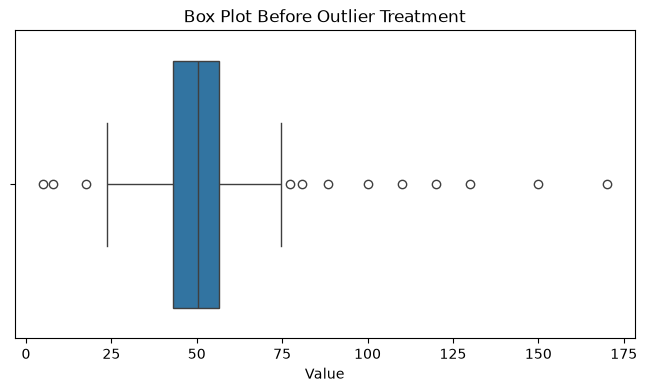

In [31]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['Value'])

plt.title("Box Plot Before Outlier Treatment")
plt.show()

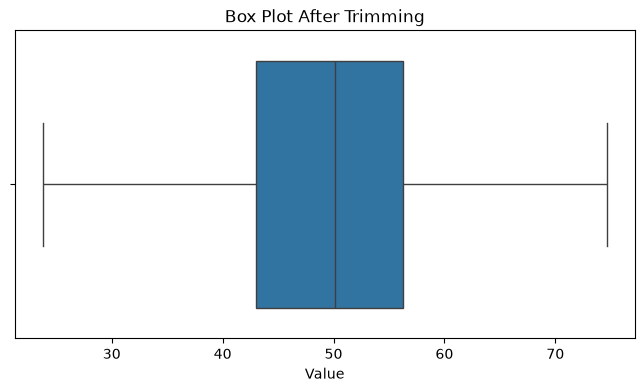

Before trimming: 508
After trimming: 496


In [ ]:
df_trimmed = df[
    (df['Value'] >= lower_bound) &
    (df['Value'] <= upper_bound)
].copy()

plt.figure(figsize=(8, 4))

sns.boxplot(x=df_trimmed['Value'])

plt.title("Box Plot After Trimming")
plt.show()

print("Before trimming:", len(df))
print("After trimming:", len(df_trimmed))


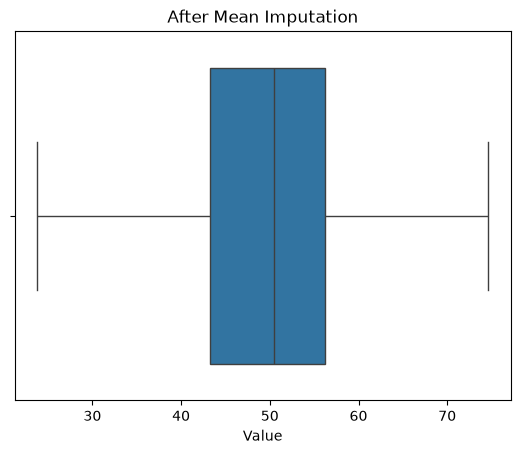

In [ ]:
df_mean = df.copy()

mean_value = df['Value'].mean()

outlier_mask = (
    (df_mean['Value'] < lower_bound) |
    (df_mean['Value'] > upper_bound)
)

df_mean.loc[outlier_mask, 'Value'] = mean_value

sns.boxplot(x=df_mean['Value'])
plt.title("After Mean Imputation")
plt.show()

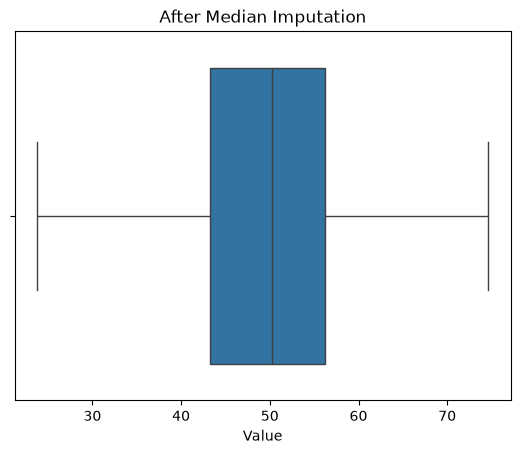

In [ ]:
df_median = df.copy()

median_value = df['Value'].median()

outlier_mask = (
    (df_median['Value'] < lower_bound) |
    (df_median['Value'] > upper_bound)
)

df_median.loc[outlier_mask, 'Value'] = median_value

sns.boxplot(x=df_median['Value'])
plt.title("After Median Imputation")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
np.random.seed(42)

n = 1200

area_sqft = np.random.normal(1500, 350, n).clip(500, 3500)
bedrooms = np.random.randint(1, 6, n)
age_years = np.random.randint(0, 40, n)
location_score = np.random.uniform(1, 10, n)

price_lakh = (
    0.055 * area_sqft
    + 7 * bedrooms
    - 0.8 * age_years
    + 9 * location_score
    + np.random.normal(0, 12, n)
)

luxury = np.random.rand(n) < 0.04

area_sqft[luxury] *= np.random.uniform(2, 3, luxury.sum())
price_lakh[luxury] += np.random.uniform(100, 250, luxury.sum())

df = pd.DataFrame({
    'area_sqft': area_sqft,
    'bedrooms': bedrooms,
    'age_years': age_years,
    'location_score': location_score,
    'price_lakh': price_lakh
})

df.head()

,area_sqft,bedrooms,age_years,location_score,price_lakh
0,1673.849954,5,37,7.730149,184.472477
1,1451.607495,2,10,8.292327,159.112596
2,4454.459494,3,32,4.724447,353.717256
3,2033.060450,5,23,2.837499,161.967746
4,1418.046319,5,22,1.381081,130.044855


In [36]:
Q1 = df['area_sqft'].quantile(0.25)
Q3 = df['area_sqft'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['area_sqft'] < lower_bound) |
    (df['area_sqft'] > upper_bound)
]

print("Outliers:", len(outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Outliers: 53
Lower bound: 560.5441818534656
Upper bound: 2504.993497045777


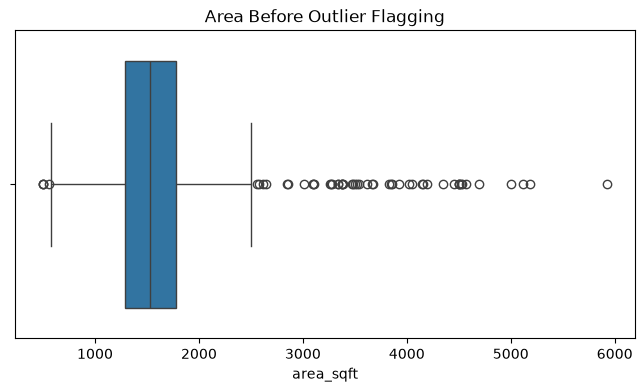

In [37]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['area_sqft'])

plt.title("Area Before Outlier Flagging")
plt.show()

In [38]:
df['is_outlier'] = (
    (df['area_sqft'] < lower_bound) |
    (df['area_sqft'] > upper_bound)
).astype(int)

df.head()

,area_sqft,bedrooms,age_years,location_score,price_lakh,is_outlier
0,1673.849954,5,37,7.730149,184.472477,0
1,1451.607495,2,10,8.292327,159.112596,0
2,4454.459494,3,32,4.724447,353.717256,1
3,2033.060450,5,23,2.837499,161.967746,0
4,1418.046319,5,22,1.381081,130.044855,0


In [39]:
X_without_flag = df.drop(columns=['price_lakh', 'is_outlier'])

X_with_flag = df.drop(columns=['price_lakh'])

y = df['price_lakh']

In [40]:
X_train_without, X_test_without, y_train, y_test = train_test_split(
    X_without_flag,
    y,
    test_size=0.2,
    random_state=42
)

X_train_with, X_test_with, _, _ = train_test_split(
    X_with_flag,
    y,
    test_size=0.2,
    random_state=42
)

In [41]:
model_without_flag = LinearRegression()

model_without_flag.fit(
    X_train_without,
    y_train
)

y_pred_without = model_without_flag.predict(
    X_test_without
)
model_with_flag = LinearRegression()

model_with_flag.fit(
    X_train_with,
    y_train
)

y_pred_with = model_with_flag.predict(
    X_test_with
)

In [42]:
results = pd.DataFrame({
    'Model': ['Without Flag', 'With Flag'],

    'MAE': [
        mean_absolute_error(y_test, y_pred_without),
        mean_absolute_error(y_test, y_pred_with)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_without)),
        np.sqrt(mean_squared_error(y_test, y_pred_with))
    ],

    'R2': [
        r2_score(y_test, y_pred_without),
        r2_score(y_test, y_pred_with)
    ]
})

results

,Model,MAE,RMSE,R2
0,Without Flag,11.890223,18.119376,0.869348
1,With Flag,11.498218,16.862420,0.886846
